In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv(
    r"C:\Users\Appex\Documents\sales_dataset.csv",
    encoding="unicode_escape"
)


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11251 entries, 0 to 11250
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           11251 non-null  int64  
 1   Cust_name         11251 non-null  str    
 2   Product_ID        11251 non-null  str    
 3   Gender            11251 non-null  str    
 4   Age               11251 non-null  int64  
 5   Marital_Status    11251 non-null  int64  
 6   State             11251 non-null  str    
 7   Occupation        11251 non-null  str    
 8   Product_Category  11251 non-null  str    
 9   Orders            11251 non-null  int64  
 10  Amount            11239 non-null  float64
 11  Status            0 non-null      float64
 12  unnamed1          0 non-null      float64
dtypes: float64(3), int64(4), str(6)
memory usage: 1.1 MB


In [4]:
df.head()

,User_ID,Cust_name,Product_ID,Gender,Age,Marital_Status,State,Occupation,Product_Category,Orders,Amount,Status,unnamed1
0,1002903,Sanskriti,P00125942,F,28,0,Maharashtra,Healthcare,Auto,1,23952.0,NaN,NaN
1,1000732,Kartik,P00110942,F,35,1,Andhra Pradesh,Govt,Auto,3,23934.0,NaN,NaN
2,1001990,Bindu,P00118542,F,35,1,Uttar Pradesh,Automobile,Auto,3,23924.0,NaN,NaN
3,1001425,Sudevi,P00237842,M,16,0,Karnataka,Construction,Auto,2,23912.0,NaN,NaN
4,1000588,Joni,P00057942,M,28,1,Gujarat,Food Processing,Auto,2,23877.0,NaN,NaN


## 3. Data Cleaning

First, unnecessary columns are removed, then missing values are checked and handled.


In [5]:
df.drop(["Status", "unnamed1"], axis=1, inplace=True)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11251 entries, 0 to 11250
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           11251 non-null  int64  
 1   Cust_name         11251 non-null  str    
 2   Product_ID        11251 non-null  str    
 3   Gender            11251 non-null  str    
 4   Age               11251 non-null  int64  
 5   Marital_Status    11251 non-null  int64  
 6   State             11251 non-null  str    
 7   Occupation        11251 non-null  str    
 8   Product_Category  11251 non-null  str    
 9   Orders            11251 non-null  int64  
 10  Amount            11239 non-null  float64
dtypes: float64(1), int64(4), str(6)
memory usage: 967.0 KB


In [7]:
df.isnull().sum()

User_ID              0
Cust_name            0
Product_ID           0
Gender               0
Age                  0
Marital_Status       0
State                0
Occupation           0
Product_Category     0
Orders               0
Amount              12
dtype: int64

In [8]:
df.dropna(inplace=True)

In [9]:
df.isnull().sum()

User_ID             0
Cust_name           0
Product_ID          0
Gender              0
Age                 0
Marital_Status      0
State               0
Occupation          0
Product_Category    0
Orders              0
Amount              0
dtype: int64

In [10]:
df.columns

Index(['User_ID', 'Cust_name', 'Product_ID', 'Gender', 'Age', 'Marital_Status',
       'State', 'Occupation', 'Product_Category', 'Orders', 'Amount'],
      dtype='str')

In [11]:
df.rename(
    columns={
        "Product_Category": "Category",
        "Cust_name": "Name",
        "User_ID": "Customer_ID"
    },
    inplace=True
)

In [12]:
df[["Age", "Orders", "Amount"]].describe()

,Age,Orders,Amount
count,11239.000000,11239.000000,11239.000000
mean,35.410357,2.489634,9453.610858
std,12.753866,1.114967,5222.355869
min,12.000000,1.000000,188.000000
25%,27.000000,2.000000,5443.000000
50%,33.000000,2.000000,8109.000000
75%,43.000000,3.000000,12675.000000
max,92.000000,4.000000,23952.000000


In [13]:
df["Gender"].unique()

<StringArray>
['F', 'M']
Length: 2, dtype: str

In [14]:
gender_map = {"M": "Male", "F": "Female"}
df["Gender"] = df["Gender"].map(gender_map)

In [15]:
df["Gender"].value_counts()

Gender
Female    7832
Male      3407
Name: count, dtype: int64

In [16]:
df["Gender"]

0        Female
1        Female
2        Female
3          Male
4          Male
          ...  
11246      Male
11247      Male
11248    Female
11249      Male
11250    Female
Name: Gender, Length: 11239, dtype: str

In [17]:
df["Marital_Status"].unique()

array([0, 1])

In [18]:
marital_map = {0: "Married", 1: "Single"}
df["Marital_Status"] = df["Marital_Status"].map(marital_map)

In [19]:
df["Marital_Status"].value_counts()

Marital_Status
Married    6518
Single     4721
Name: count, dtype: int64

In [20]:
df.head()

,Customer_ID,Name,Product_ID,Gender,Age,Marital_Status,State,Occupation,Category,Orders,Amount
0,1002903,Sanskriti,P00125942,Female,28,Married,Maharashtra,Healthcare,Auto,1,23952.0
1,1000732,Kartik,P00110942,Female,35,Single,Andhra Pradesh,Govt,Auto,3,23934.0
2,1001990,Bindu,P00118542,Female,35,Single,Uttar Pradesh,Automobile,Auto,3,23924.0
3,1001425,Sudevi,P00237842,Male,16,Married,Karnataka,Construction,Auto,2,23912.0
4,1000588,Joni,P00057942,Male,28,Single,Gujarat,Food Processing,Auto,2,23877.0


In [21]:
df

,Customer_ID,Name,Product_ID,Gender,Age,Marital_Status,State,Occupation,Category,Orders,Amount
0,1002903,Sanskriti,P00125942,Female,28,Married,Maharashtra,Healthcare,Auto,1,23952.0
1,1000732,Kartik,P00110942,Female,35,Single,Andhra Pradesh,Govt,Auto,3,23934.0
2,1001990,Bindu,P00118542,Female,35,Single,Uttar Pradesh,Automobile,Auto,3,23924.0
3,1001425,Sudevi,P00237842,Male,16,Married,Karnataka,Construction,Auto,2,23912.0
4,1000588,Joni,P00057942,Male,28,Single,Gujarat,Food Processing,Auto,2,23877.0
...,...,...,...,...,...,...,...,...,...,...,...
11246,1000695,Manning,P00296942,Male,19,Single,Maharashtra,Chemical,Office,4,370.0
11247,1004089,Reichenbach,P00171342,Male,33,Married,Haryana,Healthcare,Veterinary,3,367.0
11248,1001209,Oshin,P00201342,Female,40,Married,Madhya Pradesh,Textile,Office,4,213.0
11249,1004023,Noonan,P00059442,Male,37,Married,Karnataka,Agriculture,Office,3,206.0


In [22]:
df["State"].unique()

<StringArray>
[     'Maharashtra',   'Andhra Pradesh',    'Uttar Pradesh',
        'Karnataka',          'Gujarat', 'Himachal Pradesh',
            'Delhi',        'Jharkhand',           'Kerala',
          'Haryana',   'Madhya Pradesh',            'Bihar',
        'Rajasthan',      'Uttarakhand',        'Telangana',
           'Punjab']
Length: 16, dtype: str

In [23]:
zone_mapping = {
    "Maharashtra": "Western",
    "Gujarat": "Western",
    "Andhra Pradesh": "Southern",
    "Karnataka": "Southern",
    "Kerala": "Southern",
    "Telangana": "Southern",
    "Himachal Pradesh": "Northern",
    "Delhi": "Northern",
    "Haryana": "Northern",
    "Punjab": "Northern",
    "Uttarakhand": "Northern",
    "Rajasthan": "Northern",
    "Uttar Pradesh": "Central",
    "Madhya Pradesh": "Central",
    "Jharkhand": "Eastern",
    "Bihar": "Eastern"
}

df["Zone"] = df["State"].map(zone_mapping)


In [24]:
df["Age"].min(), df["Age"].max()

(np.int64(12), np.int64(92))

In [25]:
age_bins = [11, 18, 25, 35, 50, 65, 92]
age_labels = ["Teen", "Young Adult", "Adult", "Middle Age", "Senior", "Elderly"]

df["Age_Group"] = pd.cut(
    df["Age"],
    bins=age_bins,
    labels=age_labels
)


In [26]:
df.head()

,Customer_ID,Name,Product_ID,Gender,Age,Marital_Status,State,Occupation,Category,Orders,Amount,Zone,Age_Group
0,1002903,Sanskriti,P00125942,Female,28,Married,Maharashtra,Healthcare,Auto,1,23952.0,Western,Adult
1,1000732,Kartik,P00110942,Female,35,Single,Andhra Pradesh,Govt,Auto,3,23934.0,Southern,Adult
2,1001990,Bindu,P00118542,Female,35,Single,Uttar Pradesh,Automobile,Auto,3,23924.0,Central,Adult
3,1001425,Sudevi,P00237842,Male,16,Married,Karnataka,Construction,Auto,2,23912.0,Southern,Teen
4,1000588,Joni,P00057942,Male,28,Single,Gujarat,Food Processing,Auto,2,23877.0,Western,Adult


# Exploratory Data Analysis




In [27]:
import matplotlib.pyplot as plt 
%matplotlib inline
import seaborn as sns

## Gender

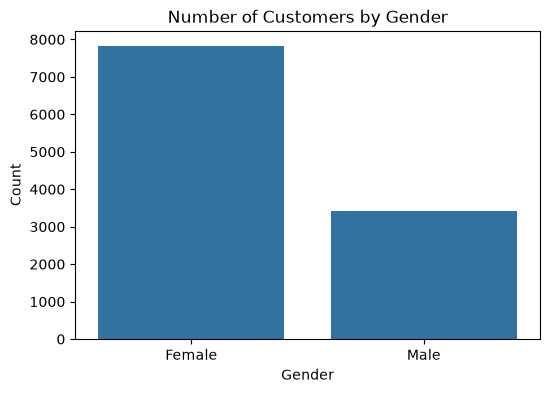

In [28]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Gender")
plt.title("Number of Customers by Gender")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()


### Sales by Gender

In [29]:
gender_sales = df.groupby("Gender").agg(
    Orders=("Orders", "sum"),
    Sales=("Amount", "sum"),
    Average_Sale=("Amount", "mean")
).sort_values("Sales", ascending=False)

gender_sales


,Orders,Sales,Average_Sale
Gender,,,
Female,19548,74335856.43,9491.299340
Male,8433,31913276.00,9366.972703


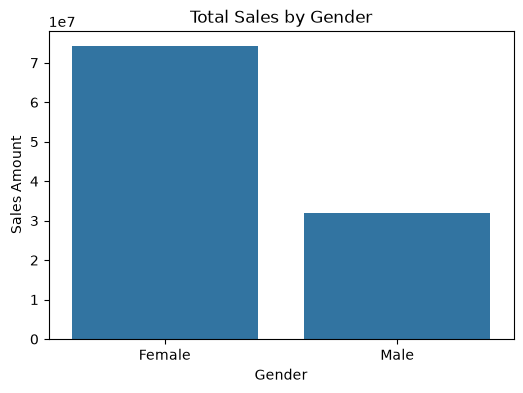

In [30]:
plt.figure(figsize=(6, 4))
sns.barplot(x=gender_sales.index, y=gender_sales["Sales"])
plt.title("Total Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Sales Amount")
plt.show()


Female customers contribute a higher total sales amount than male customers in this dataset.  
The average sale is also included above so that total sales are not confused with individual purchasing power.


## Age Group

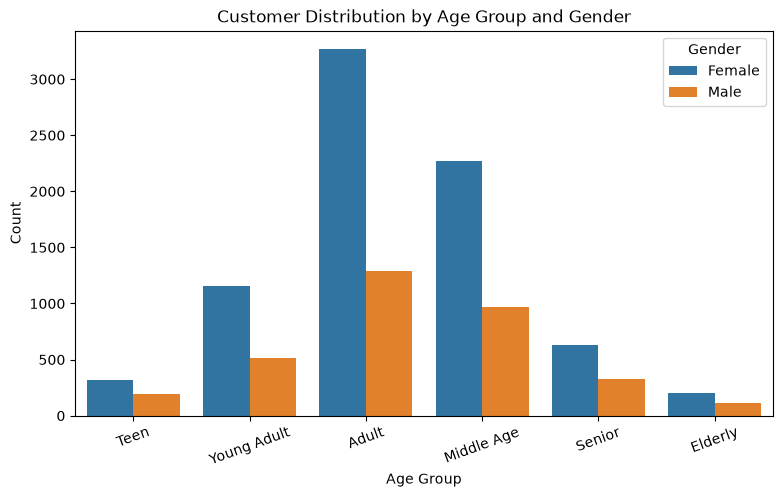

In [31]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="Age_Group", hue="Gender")
plt.title("Customer Distribution by Age Group and Gender")
plt.xlabel("Age Group")
plt.ylabel("Count")
plt.xticks(rotation=20)
plt.show()


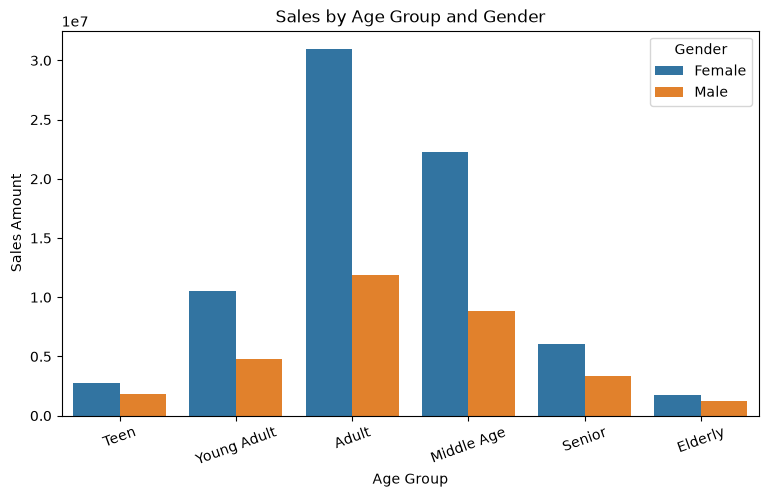

In [32]:
age_sales = df.groupby(["Age_Group", "Gender"], observed=False)["Amount"].sum().reset_index()

plt.figure(figsize=(9, 5))
sns.barplot(data=age_sales, x="Age_Group", y="Amount", hue="Gender")
plt.title("Sales by Age Group and Gender")
plt.xlabel("Age Group")
plt.ylabel("Sales Amount")
plt.xticks(rotation=20)
plt.show()


The 25–35 age group contributes a substantial share of sales for both female and male customers.  
The comparison is based on total sales amount within each age group.


## State-wise Analysis

In [33]:
state_analysis = df.groupby("State").agg(
    Orders=("Orders", "sum"),
    Sales=("Amount", "sum")
).sort_values("Orders", ascending=False)

state_analysis.head(10)


,Orders,Sales
State,,
Uttar Pradesh,4807,19374968.00
Maharashtra,3810,14427543.00
Karnataka,3240,13523540.00
Delhi,2740,11603819.45
Madhya Pradesh,2252,8101142.00
Andhra Pradesh,2051,8037146.99
Himachal Pradesh,1568,4963368.00
Kerala,1137,3894491.99
Haryana,1109,4220175.00


### Total Sales by State

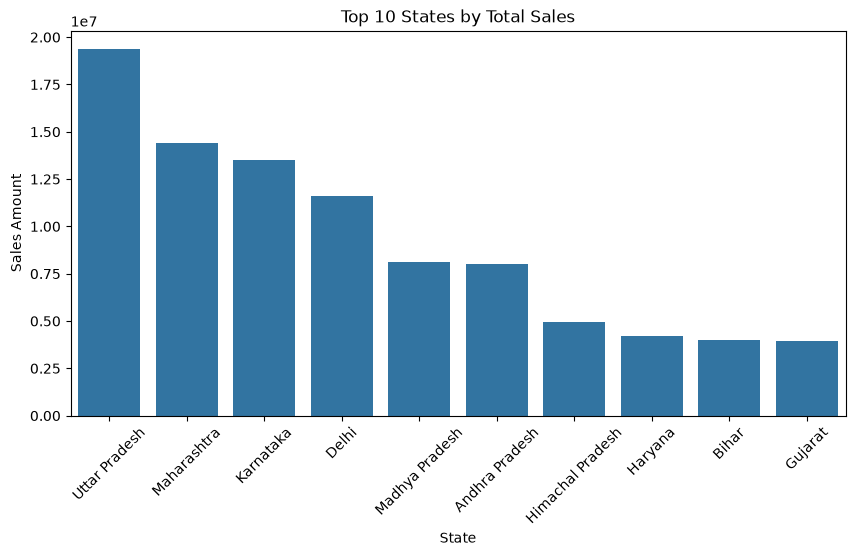

In [34]:
state_sales = state_analysis.sort_values("Sales", ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(data=state_sales, x=state_sales.index, y="Sales")
plt.title("Top 10 States by Total Sales")
plt.xlabel("State")
plt.ylabel("Sales Amount")
plt.xticks(rotation=45)
plt.show()


### Average Sales per Order by State


In [35]:
state_analysis["Average_Sales_per_Order"] = (
    state_analysis["Sales"] / state_analysis["Orders"]
)

state_analysis.sort_values(
    "Average_Sales_per_Order",
    ascending=False
).head(10)


,Orders,Sales,Average_Sales_per_Order
State,,,
Delhi,2740,11603819.45,4234.970602
Karnataka,3240,13523540.00,4173.932099
Uttar Pradesh,4807,19374968.00,4030.573747
Andhra Pradesh,2051,8037146.99,3918.647972
Haryana,1109,4220175.00,3805.387737
Bihar,1062,4022757.00,3787.906780
Maharashtra,3810,14427543.00,3786.756693
Gujarat,1066,3946082.00,3701.765478
Telangana,312,1151490.00,3690.673077


Uttar Pradesh is among the leading states in both order volume and total sales in this dataset.  
The state-level results help identify where a larger share of sales is coming from.


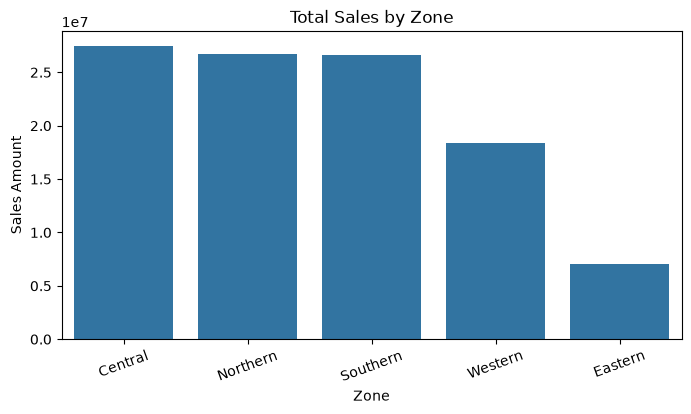

In [36]:
zone_sales = df.groupby("Zone")["Amount"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(x=zone_sales.index, y=zone_sales.values)
plt.title("Total Sales by Zone")
plt.xlabel("Zone")
plt.ylabel("Sales Amount")
plt.xticks(rotation=20)
plt.show()


The Central, Northern and Southern zones contribute large amounts to total sales in this dataset.  
The zones are custom groupings created from the state mapping above, rather than an official regional classification.


## Marital Status

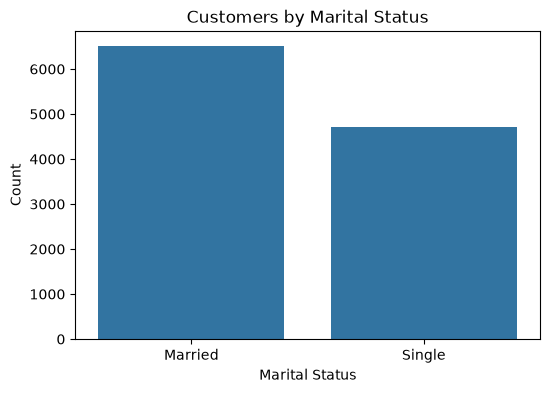

In [37]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Marital_Status")
plt.title("Customers by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Count")
plt.show()


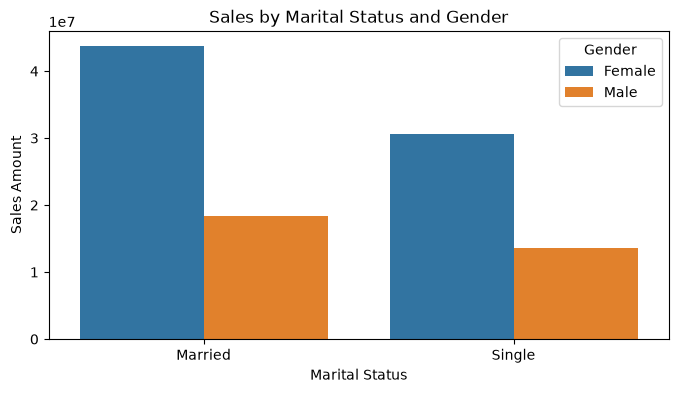

In [38]:
marital_gender_sales = df.groupby(
    ["Marital_Status", "Gender"]
)["Amount"].sum().reset_index()

plt.figure(figsize=(8, 4))
sns.barplot(
    data=marital_gender_sales,
    x="Marital_Status",
    y="Amount",
    hue="Gender"
)
plt.title("Sales by Marital Status and Gender")
plt.xlabel("Marital Status")
plt.ylabel("Sales Amount")
plt.show()


Married female customers contribute a large share of the sales amount in the dataset.  
This indicates that this segment is important in terms of total sales, but it should not be interpreted as higher individual purchasing power without comparing average transaction values.


## Occupation

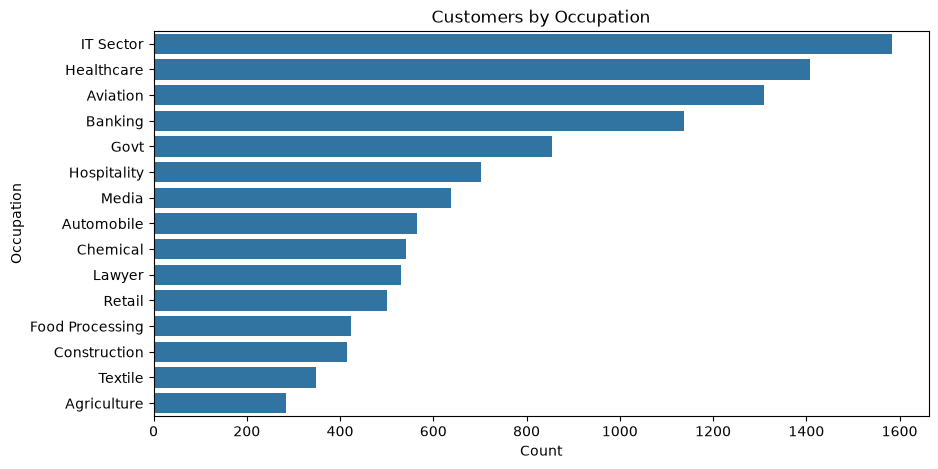

In [39]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, y="Occupation", order=df["Occupation"].value_counts().index)
plt.title("Customers by Occupation")
plt.xlabel("Count")
plt.ylabel("Occupation")
plt.show()


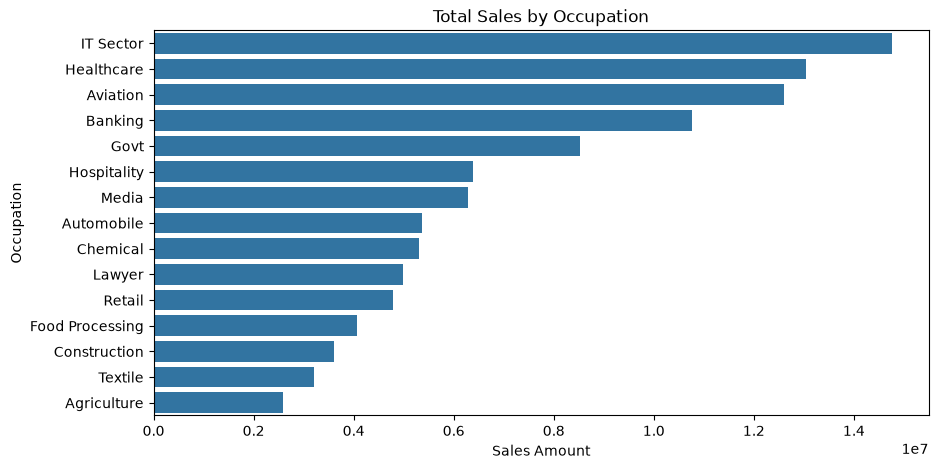

In [40]:
occupation_sales = df.groupby("Occupation")["Amount"].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=occupation_sales.values, y=occupation_sales.index)
plt.title("Total Sales by Occupation")
plt.xlabel("Sales Amount")
plt.ylabel("Occupation")
plt.show()


IT, Aviation and Healthcare are among the important occupations in terms of customer count and total sales in this dataset.


## Product Category

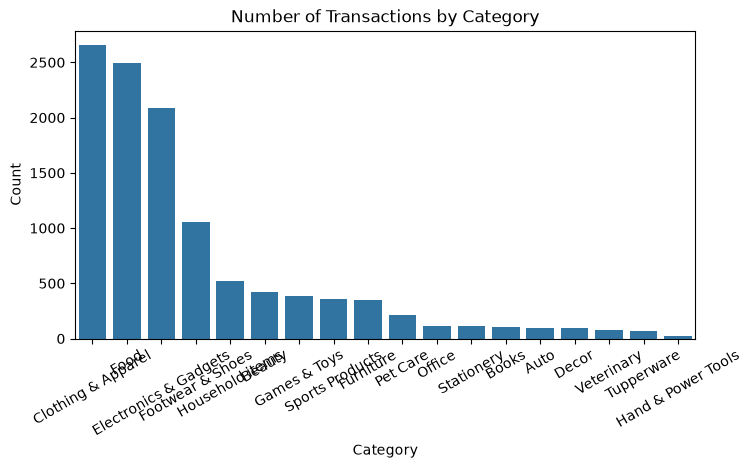

In [41]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="Category", order=df["Category"].value_counts().index)
plt.title("Number of Transactions by Category")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=30)
plt.show()


In [42]:
category_analysis = df.groupby("Category").agg(
    Orders=("Orders", "sum"),
    Sales=("Amount", "sum")
).sort_values("Sales", ascending=False)

category_analysis


,Orders,Sales
Category,,
Food,6110,33933883.50
Clothing & Apparel,6634,16495019.00
Electronics & Gadgets,5226,15643846.00
Footwear & Shoes,2646,15575209.45
Furniture,889,5440051.99
Games & Toys,940,4331694.00
Sports Products,870,3635933.00
Beauty,1086,1959484.00
Auto,239,1958609.99


Food, Clothing and Electronics are among the prominent categories in the dataset.  
Looking at both order volume and sales amount gives a clearer picture than using only one measure.


## Top Products

In [43]:
df.columns

Index(['Customer_ID', 'Name', 'Product_ID', 'Gender', 'Age', 'Marital_Status',
       'State', 'Occupation', 'Category', 'Orders', 'Amount', 'Zone',
       'Age_Group'],
      dtype='str')

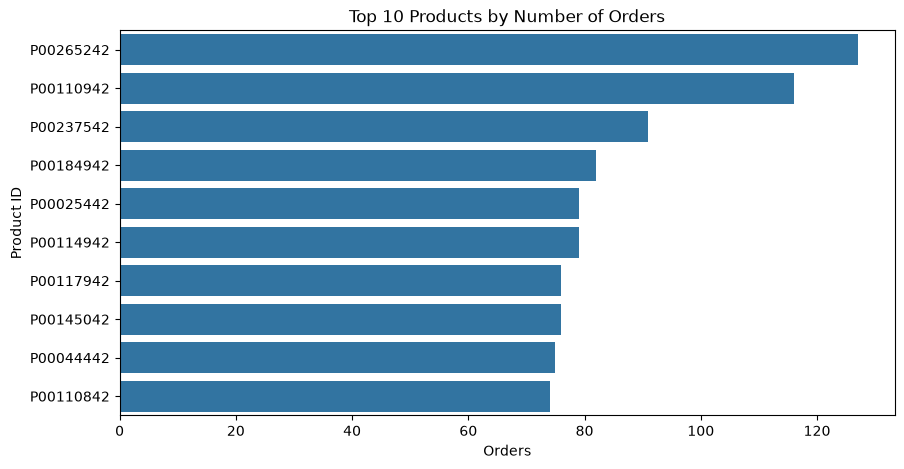

In [44]:
top_products_orders = df.groupby("Product_ID")["Orders"].sum().nlargest(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_products_orders.values, y=top_products_orders.index)
plt.title("Top 10 Products by Number of Orders")
plt.xlabel("Orders")
plt.ylabel("Product ID")
plt.show()


# 6. Key Findings

- Female customers contribute a higher total sales amount than male customers.
- Customers aged 25–35 form one of the strongest age groups in terms of sales.
- Uttar Pradesh is one of the leading states for both orders and sales.
- IT, Aviation and Healthcare are important customer segments in this dataset.
- Food, Clothing and Electronics are among the major product categories.
- Married female customers contribute strongly to the overall sales amount.


## Conclusion

The statistical analysis shows that customers’ demographics, location, occupations, and product categories have a significant impact on the company’s sales. These findings can help the company better understand its customers and group them into meaningful segments, allowing it to develop more targeted and effective marketing strategies.